In [1]:
import pandas as pd
import re

raw_path = r"C:\tri_disease_project\data\raw"
gwas = pd.read_csv(f"{raw_path}\\gwas_all.tsv", sep="\t", low_memory=False)

def build_mask(df, include_pattern, exclude_pattern):
    inc = df['DISEASE/TRAIT'].str.contains(include_pattern, case=False, regex=True, na=False) | \
          df['MAPPED_TRAIT'].str.contains(include_pattern, case=False, regex=True, na=False)
    exc = df['DISEASE/TRAIT'].str.contains(exclude_pattern, case=False, regex=True, na=False)
    return inc & ~exc

exclude_common = r'pleiotropy| or | and |pairwise|multimorbidity|response to|treated|therapy|medication|drug|in type 2 diabetes|adjusted for (?!bmi|body mass index)'

hyp_include  = r'\bhypertension\b|blood pressure|\bpulse pressure\b|mean arterial pressure'
obesity_include = r'\bobesity\b|body mass index|\bbmi\b|waist circumference|waist-to-hip|waist-hip|hip circumference'
t2d_include  = r'type 2 diabetes|type ii diabetes'

hyp_mask = build_mask(gwas, hyp_include, exclude_common)
obesity_mask = build_mask(gwas, obesity_include, exclude_common)
t2d_mask = build_mask(gwas, t2d_include, exclude_common)

print("Hypertension rows:", hyp_mask.sum())
print("Obesity rows:", obesity_mask.sum())
print("Type 2 Diabetes rows:", t2d_mask.sum())

gwas_hyp = gwas.loc[hyp_mask].copy()
gwas_obesity = gwas.loc[obesity_mask].copy()
gwas_t2d = gwas.loc[t2d_mask].copy()

print("\n--- T2D traits kept (top 25, checking composite traits are gone) ---")
print(gwas_t2d['DISEASE/TRAIT'].value_counts().head(25))

Hypertension rows: 26517
Obesity rows: 50891
Type 2 Diabetes rows: 8806

--- T2D traits kept (top 25, checking composite traits are gone) ---
DISEASE/TRAIT
Type 2 diabetes                                                      6844
Type 2 diabetes (PheCode 250.2)                                       703
Triglyceride levels in non-type 2 diabetes                            315
ICD10 E11: Non-insulin-dependent diabetes mellitus                    146
Type 2 diabetes (adjusted for BMI)                                    143
Type 2 diabetes with neurological manifestations (PheCode 250.24)     123
Type 2 diabetes with ophthalmic manifestations (PheCode 250.23)       107
Type 2 diabetes (age of onset)                                         52
Type 2 diabetes with renal manifestations (PheCode 250.22)             45
Type ii diabetes                                                       38
Type 1 diabetes                                                        26
Type 2 diabetes (SNP x SNP int

In [2]:
def extract_gwas_genes(df):
    d = df[['MAPPED_GENE', 'P-VALUE']].dropna(subset=['MAPPED_GENE']).copy()
    d['gene_list'] = d['MAPPED_GENE'].str.split(r',\s*|\s+-\s+|\s+x\s+|;\s*')   # comma, " - ", " x ", ";"
    d = d.explode('gene_list')
    d['gene_list'] = d['gene_list'].str.strip()
    d = d[d['gene_list'] != '']
    d = d.rename(columns={'gene_list': 'symbol_raw', 'P-VALUE': 'pvalue'})
    gene_level = d.groupby('symbol_raw', as_index=False)['pvalue'].min()
    return gene_level

gwas_hyp_genes = extract_gwas_genes(gwas_hyp)
gwas_obesity_genes = extract_gwas_genes(gwas_obesity)
gwas_t2d_genes = extract_gwas_genes(gwas_t2d)

print("GWAS unique genes — Hypertension:", gwas_hyp_genes.shape[0])
print("GWAS unique genes — Obesity:", gwas_obesity_genes.shape[0])
print("GWAS unique genes — T2D:", gwas_t2d_genes.shape[0])

GWAS unique genes — Hypertension: 5867
GWAS unique genes — Obesity: 9280
GWAS unique genes — T2D: 3217


In [3]:
def extract_phegeni_genes(df):
    g1 = df[['Gene', 'Gene ID', 'P-Value']].rename(columns={'Gene': 'symbol_raw', 'Gene ID': 'entrez_id', 'P-Value': 'pvalue'})
    g2 = df[['Gene 2', 'Gene ID 2', 'P-Value']].rename(columns={'Gene 2': 'symbol_raw', 'Gene ID 2': 'entrez_id', 'P-Value': 'pvalue'})
    long_df = pd.concat([g1, g2], ignore_index=True).dropna(subset=['symbol_raw']).drop_duplicates()
    gene_level = long_df.groupby('symbol_raw', as_index=False).agg({'entrez_id': 'first', 'pvalue': 'min'})
    return gene_level

raw_path = r"C:\tri_disease_project\data\raw"
phegeni_hyp = pd.read_csv(f"{raw_path}\\PheGenI_Hypertension.tab", sep="\t")
phegeni_obesity = pd.read_csv(f"{raw_path}\\PheGenI_Obesity.tab", sep="\t")
phegeni_t2d = pd.read_csv(f"{raw_path}\\PheGenI_Diabetes.tab", sep="\t")

phegeni_hyp_genes = extract_phegeni_genes(phegeni_hyp)
phegeni_obesity_genes = extract_phegeni_genes(phegeni_obesity)
phegeni_t2d_genes = extract_phegeni_genes(phegeni_t2d)

print("PheGenI unique genes — Hypertension:", phegeni_hyp_genes.shape[0])
print("PheGenI unique genes — Obesity:", phegeni_obesity_genes.shape[0])
print("PheGenI unique genes — T2D:", phegeni_t2d_genes.shape[0])
print(phegeni_hyp_genes.head(10))

PheGenI unique genes — Hypertension: 270
PheGenI unique genes — Obesity: 434
PheGenI unique genes — T2D: 416
  symbol_raw  entrez_id        pvalue
0      ADAT1      23536  5.622445e-05
1      ADAT2     134637  5.000000e-06
2     ADGRF1     266977  1.657849e-05
3      AGAP1     116987  9.000000e-07
4      AIFM3     150209  2.277489e-05
5    ALDH1A2       8854  3.000000e-06
6  ANKRD18EP  100131031  3.000000e-06
7       ANO6     196527  1.000000e-07
8    APBB1IP      54518  3.000000e-07
9   ARHGAP42     143872  5.000000e-11


In [4]:
def extract_ot_genes(df):
    gene_level = df.groupby('symbol', as_index=False)['globalScore'].max()
    return gene_level.rename(columns={'symbol': 'symbol_raw'})

ot_hyp = pd.read_csv(f"{raw_path}\\OT_Hypertension.tsv", sep="\t")
ot_obesity = pd.read_csv(f"{raw_path}\\OT_Obesity.tsv", sep="\t")
ot_t2d = pd.read_csv(f"{raw_path}\\OT_Diabetes.tsv", sep="\t")

ot_hyp_genes = extract_ot_genes(ot_hyp)
ot_obesity_genes = extract_ot_genes(ot_obesity)
ot_t2d_genes = extract_ot_genes(ot_t2d)

print("OT unique genes — Hypertension:", ot_hyp_genes.shape[0])
print("OT unique genes — Obesity:", ot_obesity_genes.shape[0])
print("OT unique genes — T2D:", ot_t2d_genes.shape[0])
print(ot_hyp_genes.head(10))

OT unique genes — Hypertension: 4837
OT unique genes — Obesity: 7797
OT unique genes — T2D: 9472
  symbol_raw  globalScore
0       A1BG     0.001478
1        A2M     0.004724
2      A2ML1     0.004805
3       AAAS     0.001478
4    AADACL2     0.001478
5       AAK1     0.007392
6      AARS1     0.001478
7       ABAT     0.002587
8      ABCA1     0.038468
9     ABCA12     0.007761


In [5]:
# one-time install if not already: pip install mygene
import mygene
mg = mygene.MyGeneInfo()

all_symbols = set()
for d in [gwas_hyp_genes, gwas_obesity_genes, gwas_t2d_genes,
          phegeni_hyp_genes, phegeni_obesity_genes, phegeni_t2d_genes,
          ot_hyp_genes, ot_obesity_genes, ot_t2d_genes]:
    all_symbols.update(d['symbol_raw'].astype(str).unique())

all_symbols = sorted(all_symbols)
print("Total unique raw symbols across all 9 sources:", len(all_symbols))

query_result = mg.querymany(all_symbols, scopes='symbol,alias', fields='symbol,entrezgene',
                             species='human', as_dataframe=True)

query_result = query_result.reset_index().rename(columns={'query': 'symbol_raw', 'symbol': 'hgnc_symbol', 'entrezgene': 'entrez_id_std'})
query_result = query_result.drop_duplicates(subset='symbol_raw', keep='first')

mapping = query_result[['symbol_raw', 'hgnc_symbol', 'entrez_id_std']]
unresolved = mapping[mapping['hgnc_symbol'].isna()]
print("Resolved:", mapping['hgnc_symbol'].notna().sum(), "/ Unresolved:", unresolved.shape[0])
print(unresolved['symbol_raw'].tolist()[:30])

import os
os.makedirs(r"C:\tri_disease_project\data\interim", exist_ok=True)
mapping.to_csv(r"C:\tri_disease_project\data\interim\gene_symbol_mapping.csv", index=False)

Total unique raw symbols across all 9 sources: 18983


2398 input query terms found dup hits:	[('AACSP1', 2), ('ABCA17P', 2), ('ABHD15-AS1', 2), ('ABHD17AP4', 2), ('ACAT1', 2), ('ACAT2', 2), ('A
57 input query terms found no hit:	['ENSG00000145063', 'ENSG00000205959', 'ENSG00000223804', 'ENSG00000225032', 'ENSG00000230928', 'ENS


Resolved: 18926 / Unresolved: 57
['ENSG00000145063', 'ENSG00000205959', 'ENSG00000223804', 'ENSG00000225032', 'ENSG00000230928', 'ENSG00000236543', 'ENSG00000237378', 'ENSG00000251605', 'ENSG00000254051', 'ENSG00000264490', 'ENSG00000265179', 'ENSG00000272977', 'ENSG00000279284', 'ENSG00000280371', 'ENSG00000282936', 'ENSG00000284684', 'ENSG00000284779', 'ENSG00000285043', 'ENSG00000285566', 'ENSG00000285976', 'ENSG00000287562', 'ENSG00000287839', 'ENSG00000288009', 'ENSG00000288645', 'ENSG00000288654', 'ENSG00000288914', 'ENSG00000289325', 'ENSG00000289360', 'ENSG00000289490', 'ENSG00000289653']


In [6]:
unresolved_symbols = unresolved['symbol_raw'].tolist()
ensembl_ids = [s for s in unresolved_symbols if str(s).startswith('ENSG')]
still_unresolved = [s for s in unresolved_symbols if not str(s).startswith('ENSG')]

print("Ensembl IDs to re-resolve:", len(ensembl_ids))
print("Genuinely unresolved (non-Ensembl):", len(still_unresolved))
print(still_unresolved)

if ensembl_ids:
    ens_result = mg.querymany(ensembl_ids, scopes='ensembl.gene', fields='symbol,entrezgene',
                               species='human', as_dataframe=True)
    ens_result = ens_result.reset_index().rename(columns={'query': 'symbol_raw', 'symbol': 'hgnc_symbol', 'entrezgene': 'entrez_id_std'})
    ens_result = ens_result.drop_duplicates(subset='symbol_raw', keep='first')
    ens_mapping = ens_result[['symbol_raw', 'hgnc_symbol', 'entrez_id_std']]

    # merge back into the main mapping table
    mapping = mapping.set_index('symbol_raw')
    ens_mapping = ens_mapping.set_index('symbol_raw')
    mapping.update(ens_mapping)
    mapping = mapping.reset_index()

    print("\nNewly resolved from Ensembl IDs:", ens_mapping['hgnc_symbol'].notna().sum(), "/", len(ensembl_ids))

mapping.to_csv(r"C:\tri_disease_project\data\interim\gene_symbol_mapping.csv", index=False)
print("\nFinal resolved:", mapping['hgnc_symbol'].notna().sum(), "/ Final unresolved:", mapping['hgnc_symbol'].isna().sum())

Ensembl IDs to re-resolve: 36
Genuinely unresolved (non-Ensembl): 21
['FLJ12825', 'FLJ34503', 'FLJ45079', 'LOC100129940', 'LOC101927359', 'LOC101927502', 'LOC101927592', 'LOC101927676', 'LOC101927736', 'LOC101927770', 'LOC101928114', 'LOC101928423', 'LOC101928982', 'LOC101929615', 'LOC102725019', 'LOC727896', 'LOC728095', 'LOC90768', 'SNORD115', 'SNORD116', 'SNORD36']

Newly resolved from Ensembl IDs: 14 / 36

Final resolved: 18940 / Final unresolved: 43


In [7]:
import os

# build a clean lookup: symbol_raw -> hgnc_symbol
lookup = mapping.dropna(subset=['hgnc_symbol']).set_index('symbol_raw')['hgnc_symbol'].to_dict()

def standardize(df, symbol_col='symbol_raw'):
    d = df.copy()
    d['hgnc_symbol'] = d[symbol_col].map(lookup)
    d = d.dropna(subset=['hgnc_symbol'])
    return d

# apply to all 9 gene-level tables
gwas_hyp_std = standardize(gwas_hyp_genes)
gwas_obesity_std = standardize(gwas_obesity_genes)
gwas_t2d_std = standardize(gwas_t2d_genes)

phegeni_hyp_std = standardize(phegeni_hyp_genes)
phegeni_obesity_std = standardize(phegeni_obesity_genes)
phegeni_t2d_std = standardize(phegeni_t2d_genes)

ot_hyp_std = standardize(ot_hyp_genes)
ot_obesity_std = standardize(ot_obesity_genes)
ot_t2d_std = standardize(ot_t2d_genes)

def merge_disease(gwas_df, phegeni_df, ot_df, disease_name):
    g = gwas_df[['hgnc_symbol', 'pvalue']].rename(columns={'pvalue': 'gwas_pvalue'})
    g = g.groupby('hgnc_symbol', as_index=False)['gwas_pvalue'].min()

    p = phegeni_df[['hgnc_symbol', 'pvalue', 'entrez_id']].rename(columns={'pvalue': 'phegeni_pvalue'})
    p = p.groupby('hgnc_symbol', as_index=False).agg({'phegeni_pvalue': 'min', 'entrez_id': 'first'})

    o = ot_df[['hgnc_symbol', 'globalScore']].rename(columns={'globalScore': 'ot_score'})
    o = o.groupby('hgnc_symbol', as_index=False)['ot_score'].max()

    merged = g.merge(p, on='hgnc_symbol', how='outer').merge(o, on='hgnc_symbol', how='outer')
    merged['n_sources'] = merged[['gwas_pvalue', 'phegeni_pvalue', 'ot_score']].notna().sum(axis=1)
    merged['disease'] = disease_name
    return merged

hyp_table = merge_disease(gwas_hyp_std, phegeni_hyp_std, ot_hyp_std, 'Hypertension')
obesity_table = merge_disease(gwas_obesity_std, phegeni_obesity_std, ot_obesity_std, 'Obesity')
t2d_table = merge_disease(gwas_t2d_std, phegeni_t2d_std, ot_t2d_std, 'T2D')

print("Hypertension disease-level table:", hyp_table.shape)
print(hyp_table['n_sources'].value_counts().sort_index())
print(hyp_table.head())

print("\nObesity disease-level table:", obesity_table.shape)
print(obesity_table['n_sources'].value_counts().sort_index())

print("\nT2D disease-level table:", t2d_table.shape)
print(t2d_table['n_sources'].value_counts().sort_index())

os.makedirs(r"C:\tri_disease_project\data\processed", exist_ok=True)
hyp_table.to_csv(r"C:\tri_disease_project\data\processed\hypertension_master.csv", index=False)
obesity_table.to_csv(r"C:\tri_disease_project\data\processed\obesity_master.csv", index=False)
t2d_table.to_csv(r"C:\tri_disease_project\data\processed\t2d_master.csv", index=False)

print("\nSaved 3 master tables to data/processed/")

Hypertension disease-level table: (9306, 7)
n_sources
1    7845
2    1394
3      67
Name: count, dtype: int64
  hgnc_symbol  gwas_pvalue  phegeni_pvalue  entrez_id  ot_score  n_sources  \
0        A1BG          NaN             NaN        NaN  0.001478          1   
1         A2M          NaN             NaN        NaN  0.004724          1   
2       A2ML1          NaN             NaN        NaN  0.004805          1   
3        AAAS          NaN             NaN        NaN  0.001478          1   
4        AACS     0.000009             NaN        NaN       NaN          1   

        disease  
0  Hypertension  
1  Hypertension  
2  Hypertension  
3  Hypertension  
4  Hypertension  

Obesity disease-level table: (13915, 7)
n_sources
1    10720
2     3051
3      144
Name: count, dtype: int64

T2D disease-level table: (10688, 7)
n_sources
1    8737
2    1766
3     185
Name: count, dtype: int64

Saved 3 master tables to data/processed/


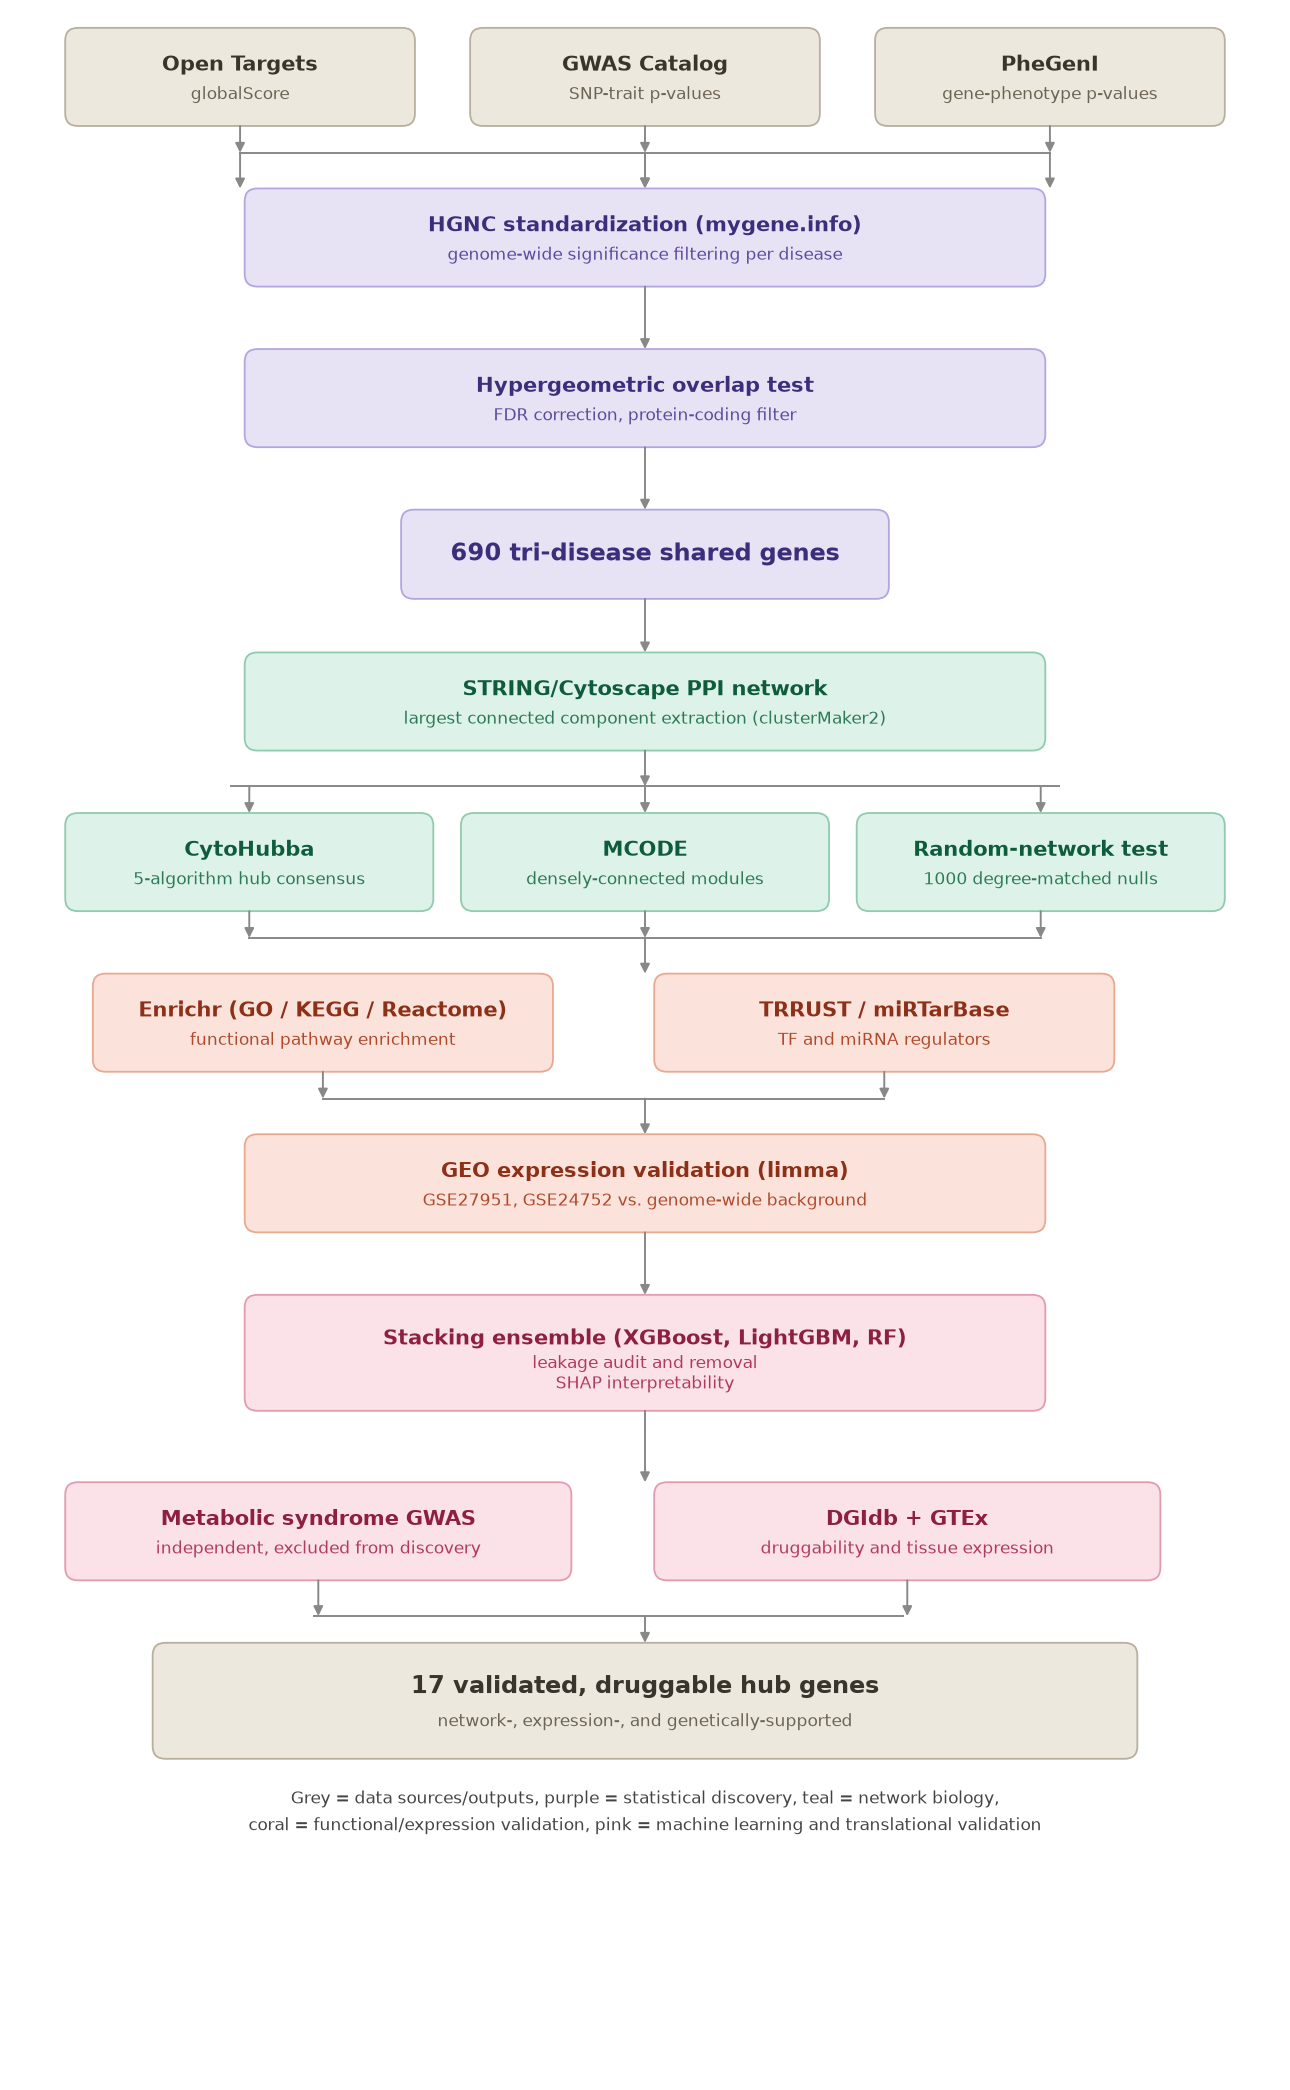

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import matplotlib.font_manager as fm

# ---------- Color palette (matching the reference image) ----------
COLORS = {
    'grey':   {'face': '#EDE8DE', 'edge': '#B8AF9E', 'title': '#3A352C', 'sub': '#6B6455'},
    'purple': {'face': '#E7E3F5', 'edge': '#B3A6DE', 'title': '#3D2E7C', 'sub': '#5B4A9E'},
    'teal':   {'face': '#DDF2E9', 'edge': '#8FCBAE', 'title': '#0F5C3C', 'sub': '#2C7A55'},
    'coral':  {'face': '#FBE3DC', 'edge': '#E8A98F', 'title': '#8C3018', 'sub': '#B0492A'},
    'pink':   {'face': '#FBE1E8', 'edge': '#E39BB0', 'title': '#8C1F42', 'sub': '#B03A5E'},
}

fig, ax = plt.subplots(figsize=(13, 21))
ax.set_xlim(0, 1380)
ax.set_ylim(0, 2320)
ax.invert_yaxis()
ax.axis('off')

def draw_box(x, y, w, h, title, subtitle, color_key, title_size=15, sub_size=12):
    c = COLORS[color_key]
    box = FancyBboxPatch((x, y), w, h,
                          boxstyle="round,pad=0,rounding_size=14",
                          linewidth=1.3, edgecolor=c['edge'], facecolor=c['face'])
    ax.add_patch(box)
    cx = x + w / 2
    if subtitle:
        ax.text(cx, y + h * 0.38, title, ha='center', va='center',
                 fontsize=title_size, fontweight='bold', color=c['title'])
        ax.text(cx, y + h * 0.68, subtitle, ha='center', va='center',
                 fontsize=sub_size, color=c['sub'])
    else:
        ax.text(cx, y + h / 2, title, ha='center', va='center',
                 fontsize=title_size, fontweight='bold', color=c['title'])
    return x, y, w, h

def arrow(x1, y1, x2, y2, color='#888888'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='-|>', color=color, lw=1.4,
                                 shrinkA=0, shrinkB=0, mutation_scale=14))

def hline(x1, x2, y, color='#888888'):
    ax.plot([x1, x2], [y, y], color=color, lw=1.4)

def bottom(box):  return (box[0] + box[2] / 2, box[1] + box[3])
def top(box):     return (box[0] + box[2] / 2, box[1])

# ---------- Tier 1: data sources ----------
b1 = draw_box(60,  20, 380, 110, "Open Targets", "globalScore", 'grey')
b2 = draw_box(500, 20, 380, 110, "GWAS Catalog", "SNP-trait p-values", 'grey')
b3 = draw_box(940, 20, 380, 110, "PheGenI", "gene-phenotype p-values", 'grey')

merge_y = 200
for b in (b1, b2, b3):
    arrow(*top((b[0], merge_y - 40, b[2], 0)), *top((b[0], merge_y, b[2], 0)))
    arrow(*bottom(b), b[0] + b[2] / 2, merge_y - 40)
hline(b1[0] + b1[2] / 2, b3[0] + b3[2] / 2, merge_y - 40)
arrow(690, merge_y - 40, 690, merge_y)

# ---------- Tier 2: statistical discovery (purple) ----------
b4 = draw_box(255, 200, 870, 110, "HGNC standardization (mygene.info)",
              "genome-wide significance filtering per disease", 'purple')
arrow(*bottom(b4), *top((b4[0], 380, b4[2], 0)))

b5 = draw_box(255, 380, 870, 110, "Hypergeometric overlap test",
              "FDR correction, protein-coding filter", 'purple')
arrow(*bottom(b5), *top((b5[0], 560, b5[2], 0)))

b6 = draw_box(425, 560, 530, 100, "690 tri-disease shared genes", "", 'purple', title_size=17)
arrow(*bottom(b6), *top((b6[0], 720, b6[2], 0)))

# ---------- Tier 3: network biology (teal) ----------
b7 = draw_box(255, 720, 870, 110, "STRING/Cytoscape PPI network",
              "largest connected component extraction (clusterMaker2)", 'teal')

merge_y2 = 900
arrow(*bottom(b7), 690, merge_y2 - 30)
hline(240, 1140, merge_y2 - 30)

b8 = draw_box(60,  900, 400, 110, "CytoHubba", "5-algorithm hub consensus", 'teal')
b9 = draw_box(490, 900, 400, 110, "MCODE", "densely-connected modules", 'teal')
b10 = draw_box(920, 900, 400, 110, "Random-network test", "1000 degree-matched nulls", 'teal')
for b in (b8, b9, b10):
    arrow(b[0] + b[2] / 2, merge_y2 - 30, *top(b))

merge_y3 = 1080
for b in (b8, b9, b10):
    arrow(*bottom(b), b[0] + b[2] / 2, merge_y3 - 40)
hline(260, 1120, merge_y3 - 40)
arrow(690, merge_y3 - 40, 690, merge_y3)

# ---------- Tier 4: functional/expression validation (coral) ----------
b11 = draw_box(90,  1080, 500, 110, "Enrichr (GO / KEGG / Reactome)",
               "functional pathway enrichment", 'coral')
b12 = draw_box(700, 1080, 500, 110, "TRRUST / miRTarBase",
               "TF and miRNA regulators", 'coral')

merge_y4 = 1260
for b in (b11, b12):
    arrow(*bottom(b), b[0] + b[2] / 2, merge_y4 - 40)
hline(340, 950, merge_y4 - 40)
arrow(690, merge_y4 - 40, 690, merge_y4)

b13 = draw_box(255, 1260, 870, 110, "GEO expression validation (limma)",
               "GSE27951, GSE24752 vs. genome-wide background", 'coral')
arrow(*bottom(b13), *top((b13[0], 1440, b13[2], 0)))

# ---------- Tier 5: machine learning & translational validation (pink) ----------
b14 = draw_box(255, 1440, 870, 130, "Stacking ensemble (XGBoost, LightGBM, RF)",
               "leakage audit and removal\nSHAP interpretability", 'pink')
arrow(*bottom(b14), *top((b14[0], 1650, b14[2], 0)))

b15 = draw_box(60,  1650, 550, 110, "Metabolic syndrome GWAS",
               "independent, excluded from discovery", 'pink')
b16 = draw_box(700, 1650, 550, 110, "DGIdb + GTEx",
               "druggability and tissue expression", 'pink')

merge_y5 = 1830
for b in (b15, b16):
    arrow(*bottom(b), b[0] + b[2] / 2, merge_y5 - 30)
hline(330, 970, merge_y5 - 30)
arrow(690, merge_y5 - 30, 690, merge_y5)

# ---------- Final output (grey) ----------
b17 = draw_box(155, 1830, 1070, 130, "17 validated, druggable hub genes",
               "network-, expression-, and genetically-supported", 'grey', title_size=17)

# ---------- Legend ----------
ax.text(690, 2010, "Grey = data sources/outputs, purple = statistical discovery, teal = network biology,",
        ha='center', fontsize=12, color='#444444')
ax.text(690, 2040, "coral = functional/expression validation, pink = machine learning and translational validation",
        ha='center', fontsize=12, color='#444444')

plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig0_architecture_diagram.png",
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()